In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

folder_path = '/content/drive/MyDrive/Lab2_Computational_Intelligence'
part2_path = folder_path + '/Part2_Detection'

for name in ['raw_images', 'models' ]:
    os.makedirs(part2_path + '/' + name, exist_ok=True)

In [4]:
import os
part2_path = '/content/drive/MyDrive/Lab2_Computational_Intelligence/Part2_Detection'
print(os.listdir(part2_path))

['raw_images', 'models', 'Lab2_Object_Detection.v1i.yolov8.zip']


In [5]:
import zipfile

zip_files = [f for f in os.listdir(part2_path) if f.endswith('.zip')]

print("ZIP files:", zip_files)

zip_path = part2_path + '/' + zip_files[0]
dataset_path = '/content/part2_dataset'

with zipfile.ZipFile(zip_path) as zip_file:
    zip_file.extractall(dataset_path)

print("Dataset extracted!")
print(os.listdir(dataset_path))


ZIP files: ['Lab2_Object_Detection.v1i.yolov8.zip']
Dataset extracted!
['test', 'README.roboflow.txt', 'data.yaml', 'valid', 'train']


In [6]:
import yaml

with open(dataset_path + '/data.yaml') as file:
    data = yaml.safe_load(file)

print("Classes:", data['names'])

Classes: ['bottle', 'cola_can', 'duck']


In [7]:
for split in ['train', 'valid', 'test']:
    folder = dataset_path + '/' + split

    images = os.listdir(folder + '/images')
    labels = [f for f in os.listdir(folder + '/labels') if f.endswith('.txt')]

    print(split, ':', len(images), 'images,', len(labels), 'label files')

train : 78 images, 78 label files
valid : 17 images, 17 label files
test : 17 images, 17 label files


***Ultralytics library***

In [8]:
!pip install -q ultralytics

In [9]:
from pathlib import Path
import yaml

yaml_path = dataset_path + '/data.yaml'

with open(yaml_path) as file:
    data = yaml.safe_load(file)

print("Classes:", data['names'])

for split in ['train', 'valid', 'test']:
    labels = list(Path(dataset_path, split, 'labels').glob('*.txt'))
    boxes = sum(len(f.read_text().splitlines()) for f in labels)

    print(split, "- Labels:", len(labels), "Boxes:", boxes)

Classes: ['bottle', 'cola_can', 'duck']
train - Labels: 78 Boxes: 118
valid - Labels: 17 Boxes: 20
test - Labels: 17 Boxes: 21


In [10]:
assert set(data['names'].values() if isinstance(data['names'], dict)
           else data['names']) == {'bottle', 'cola_can', 'duck'}

data['path'] = dataset_path
data['train'] = 'train/images'
data['val'] = 'valid/images'
data['test'] = 'test/images'

with open(yaml_path, 'w') as file:
    yaml.safe_dump(data, file)

***Load and train YOLOv8***

In [11]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

results = model.train(
    data=yaml_path,
    epochs=30,
    imgsz=640,
    batch=8,
    project='/content/yolo_runs',
    name='part2'
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/part2_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

***Save the trained model***

In [12]:
from ultralytics import YOLO

best_model = '/content/yolo_runs/part2/weights/best.pt'

model = YOLO(best_model)

model.info()
print("Classes:", model.names)

Model summary: 130 layers, 3,138,489 parameters, 0 gradients, 8.8 GFLOPs
Classes: {0: 'bottle', 1: 'cola_can', 2: 'duck'}


***Model Evaluation***

In [13]:
from ultralytics import YOLO

model = YOLO(part2_path + '/models/best.pt')

metrics = model.val(
    data=yaml_path,
    split='test',
    imgsz=640,
    plots=True
)


Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1183.9±490.0 MB/s, size: 35.7 KB)
val: Scanning /content/part2_dataset/test/labels... 17 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 2.0Kit/s 0.0s
val: New cache created: /content/part2_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.0it/s 0.7s
                   all         17         21      0.983      0.878       0.95      0.877
                bottle          7          9      0.964      0.778      0.891       0.76
              cola_can          7          7      0.996      0.857      0.964      0.946
                  duck          5          5      0.989          1      0.995      0.925
Speed: 3.2ms preprocess, 12.6ms inference, 0.0ms loss, 2.4ms postprocess per im

In [14]:
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")

Precision: 0.9831
Recall: 0.8783
mAP50: 0.9499
mAP50-95: 0.8771


In [15]:
import os

print(metrics.save_dir)
print(os.listdir(metrics.save_dir))

/content/runs/detect/val
['val_batch1_labels.jpg', 'confusion_matrix_normalized.png', 'val_batch0_labels.jpg', 'BoxP_curve.png', 'BoxR_curve.png', 'val_batch1_pred.jpg', 'BoxPR_curve.png', 'BoxF1_curve.png', 'val_batch0_pred.jpg', 'confusion_matrix.png']


Training and Validation Graphs


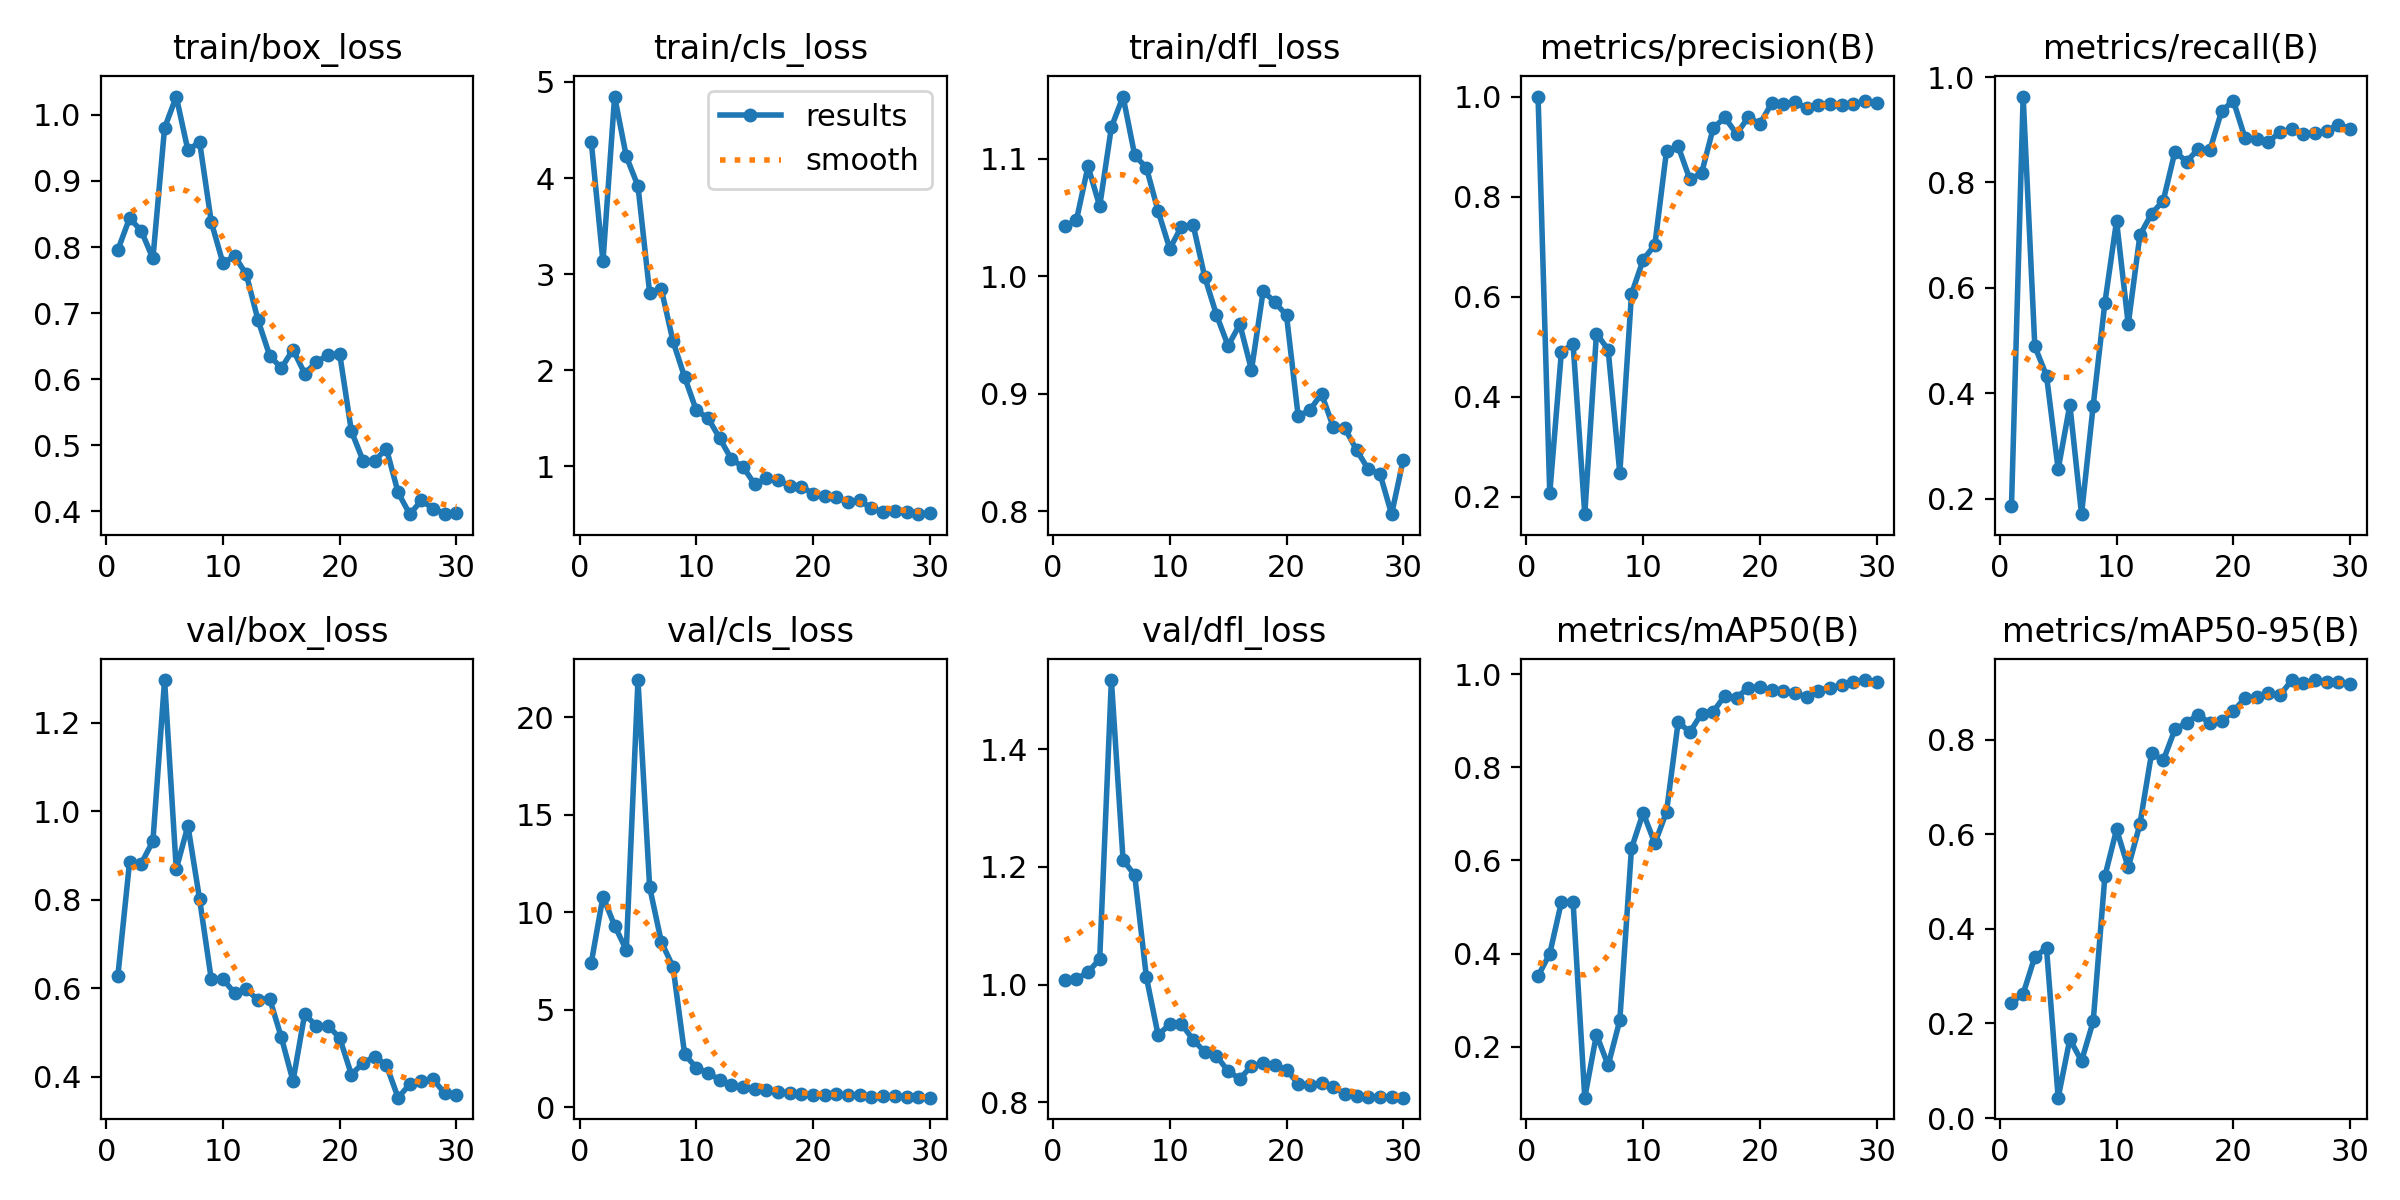

confusion_matrix.png


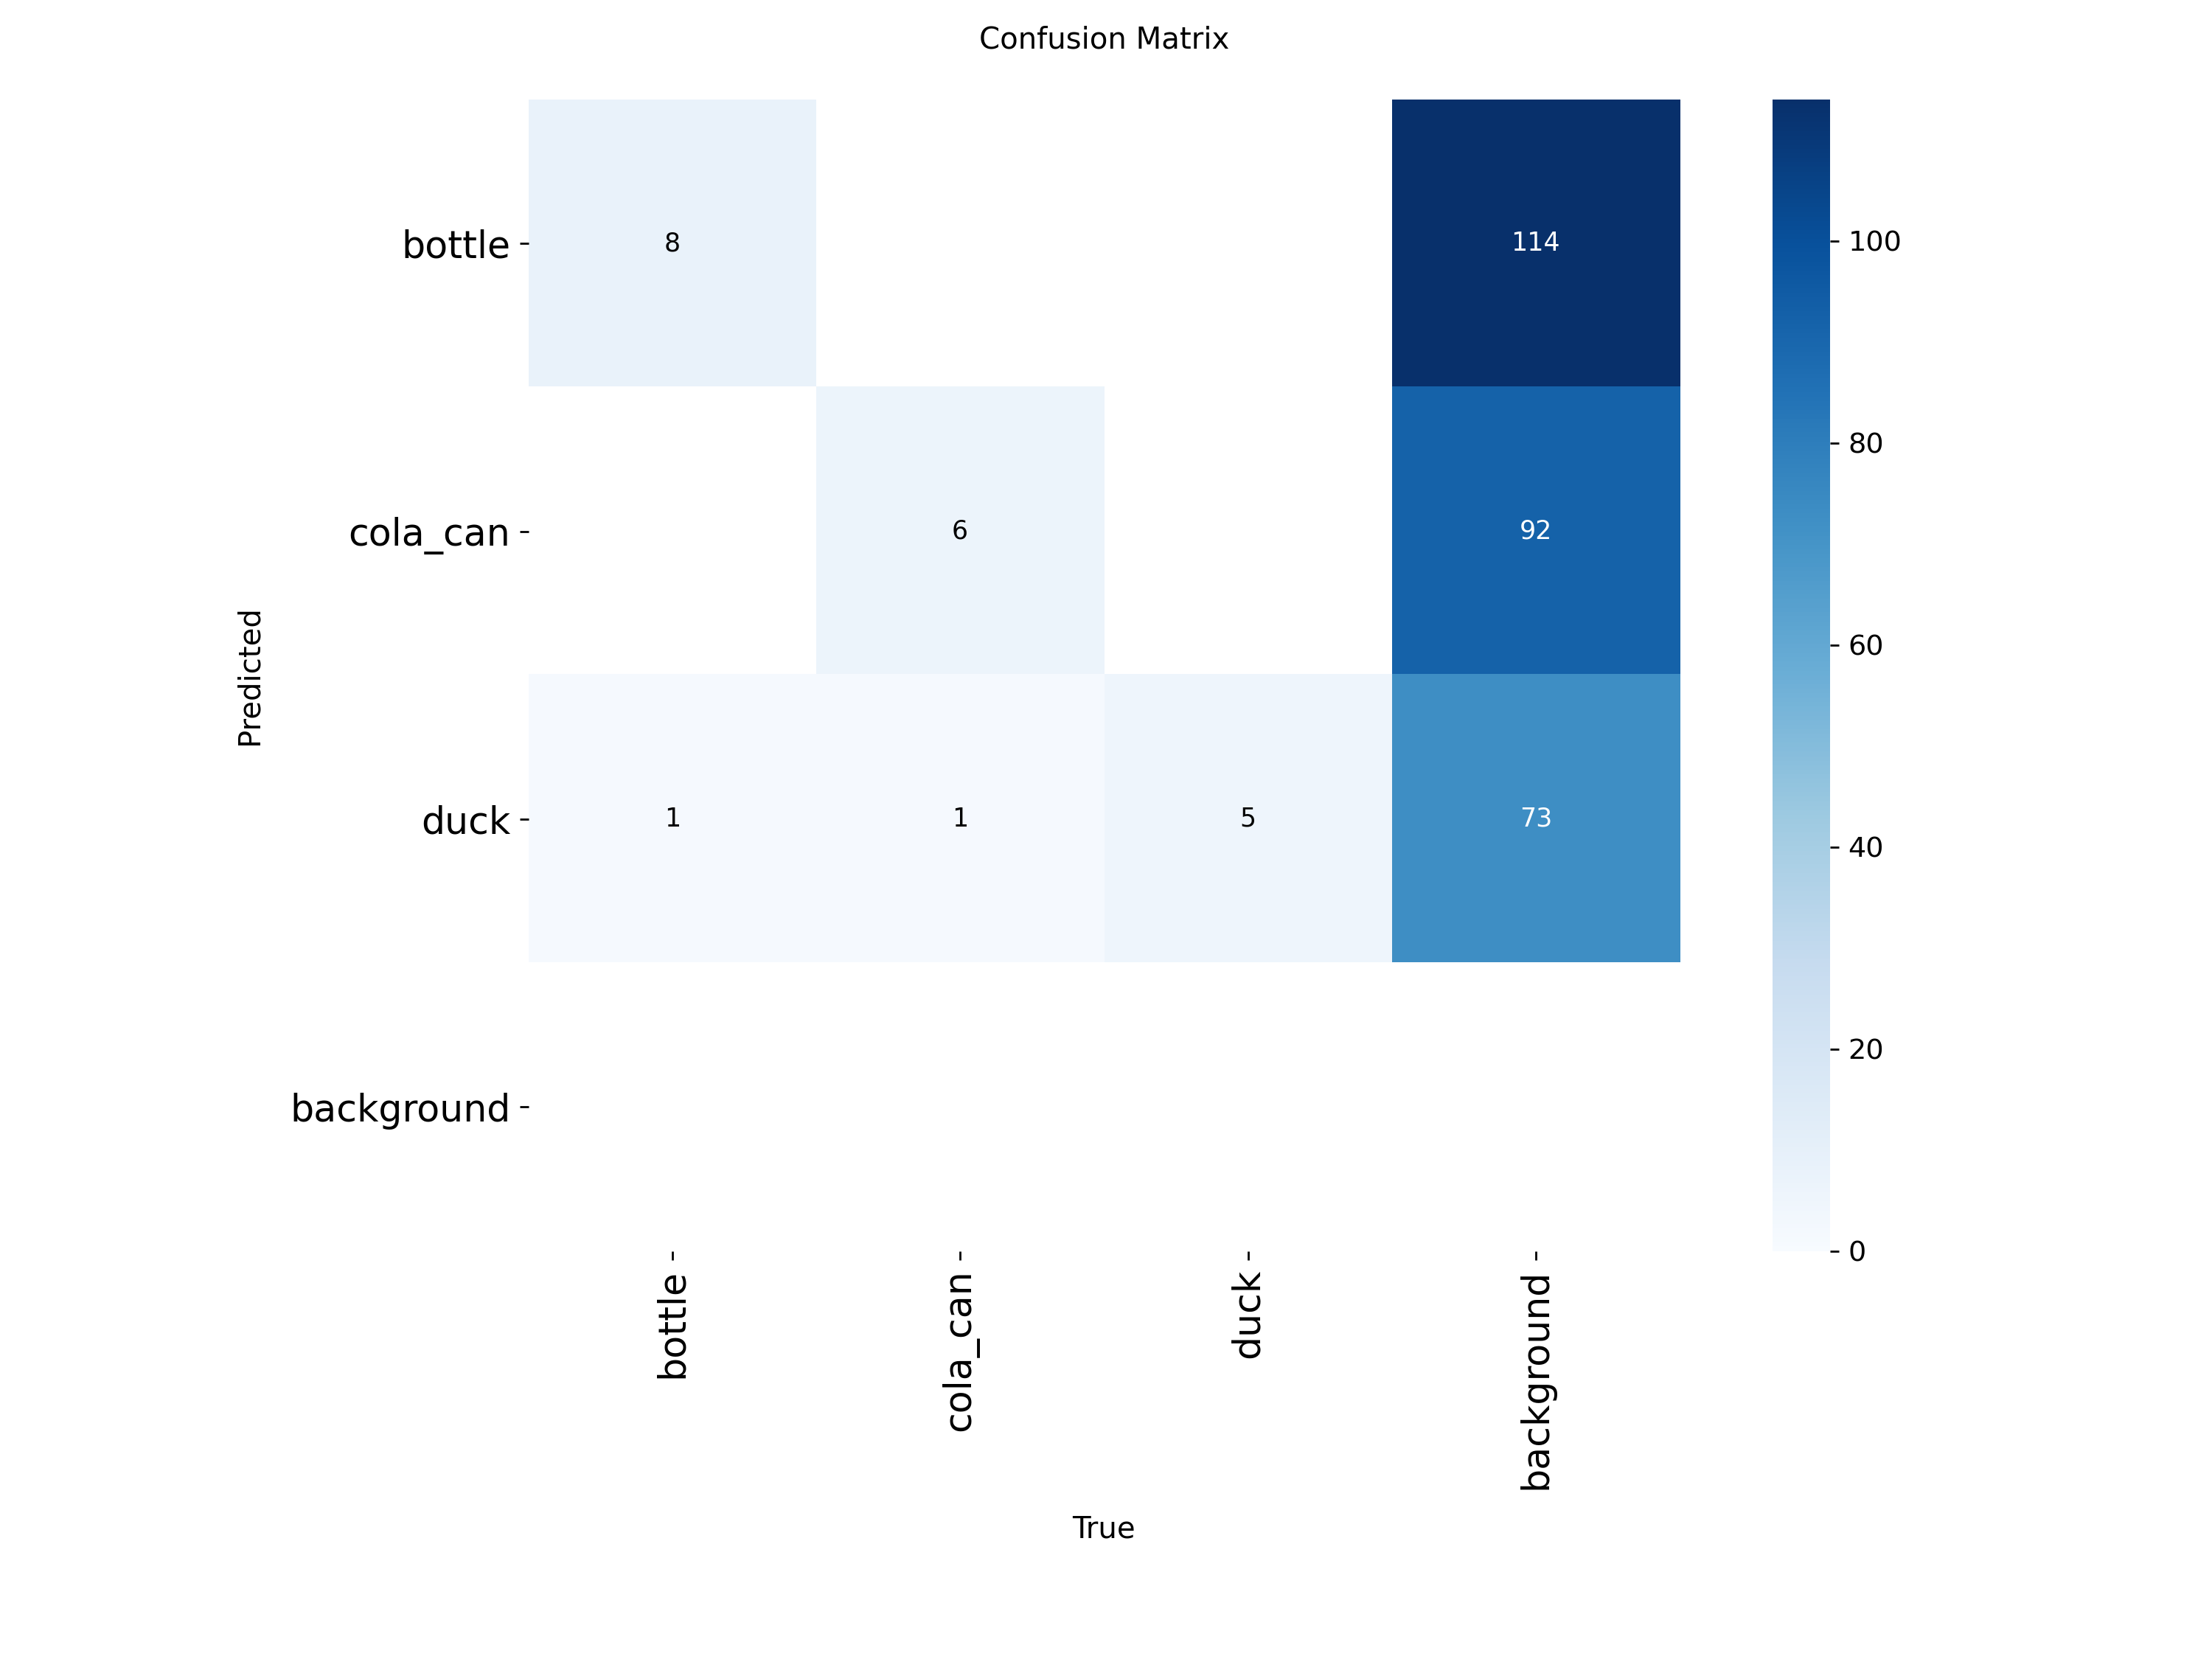

confusion_matrix_normalized.png


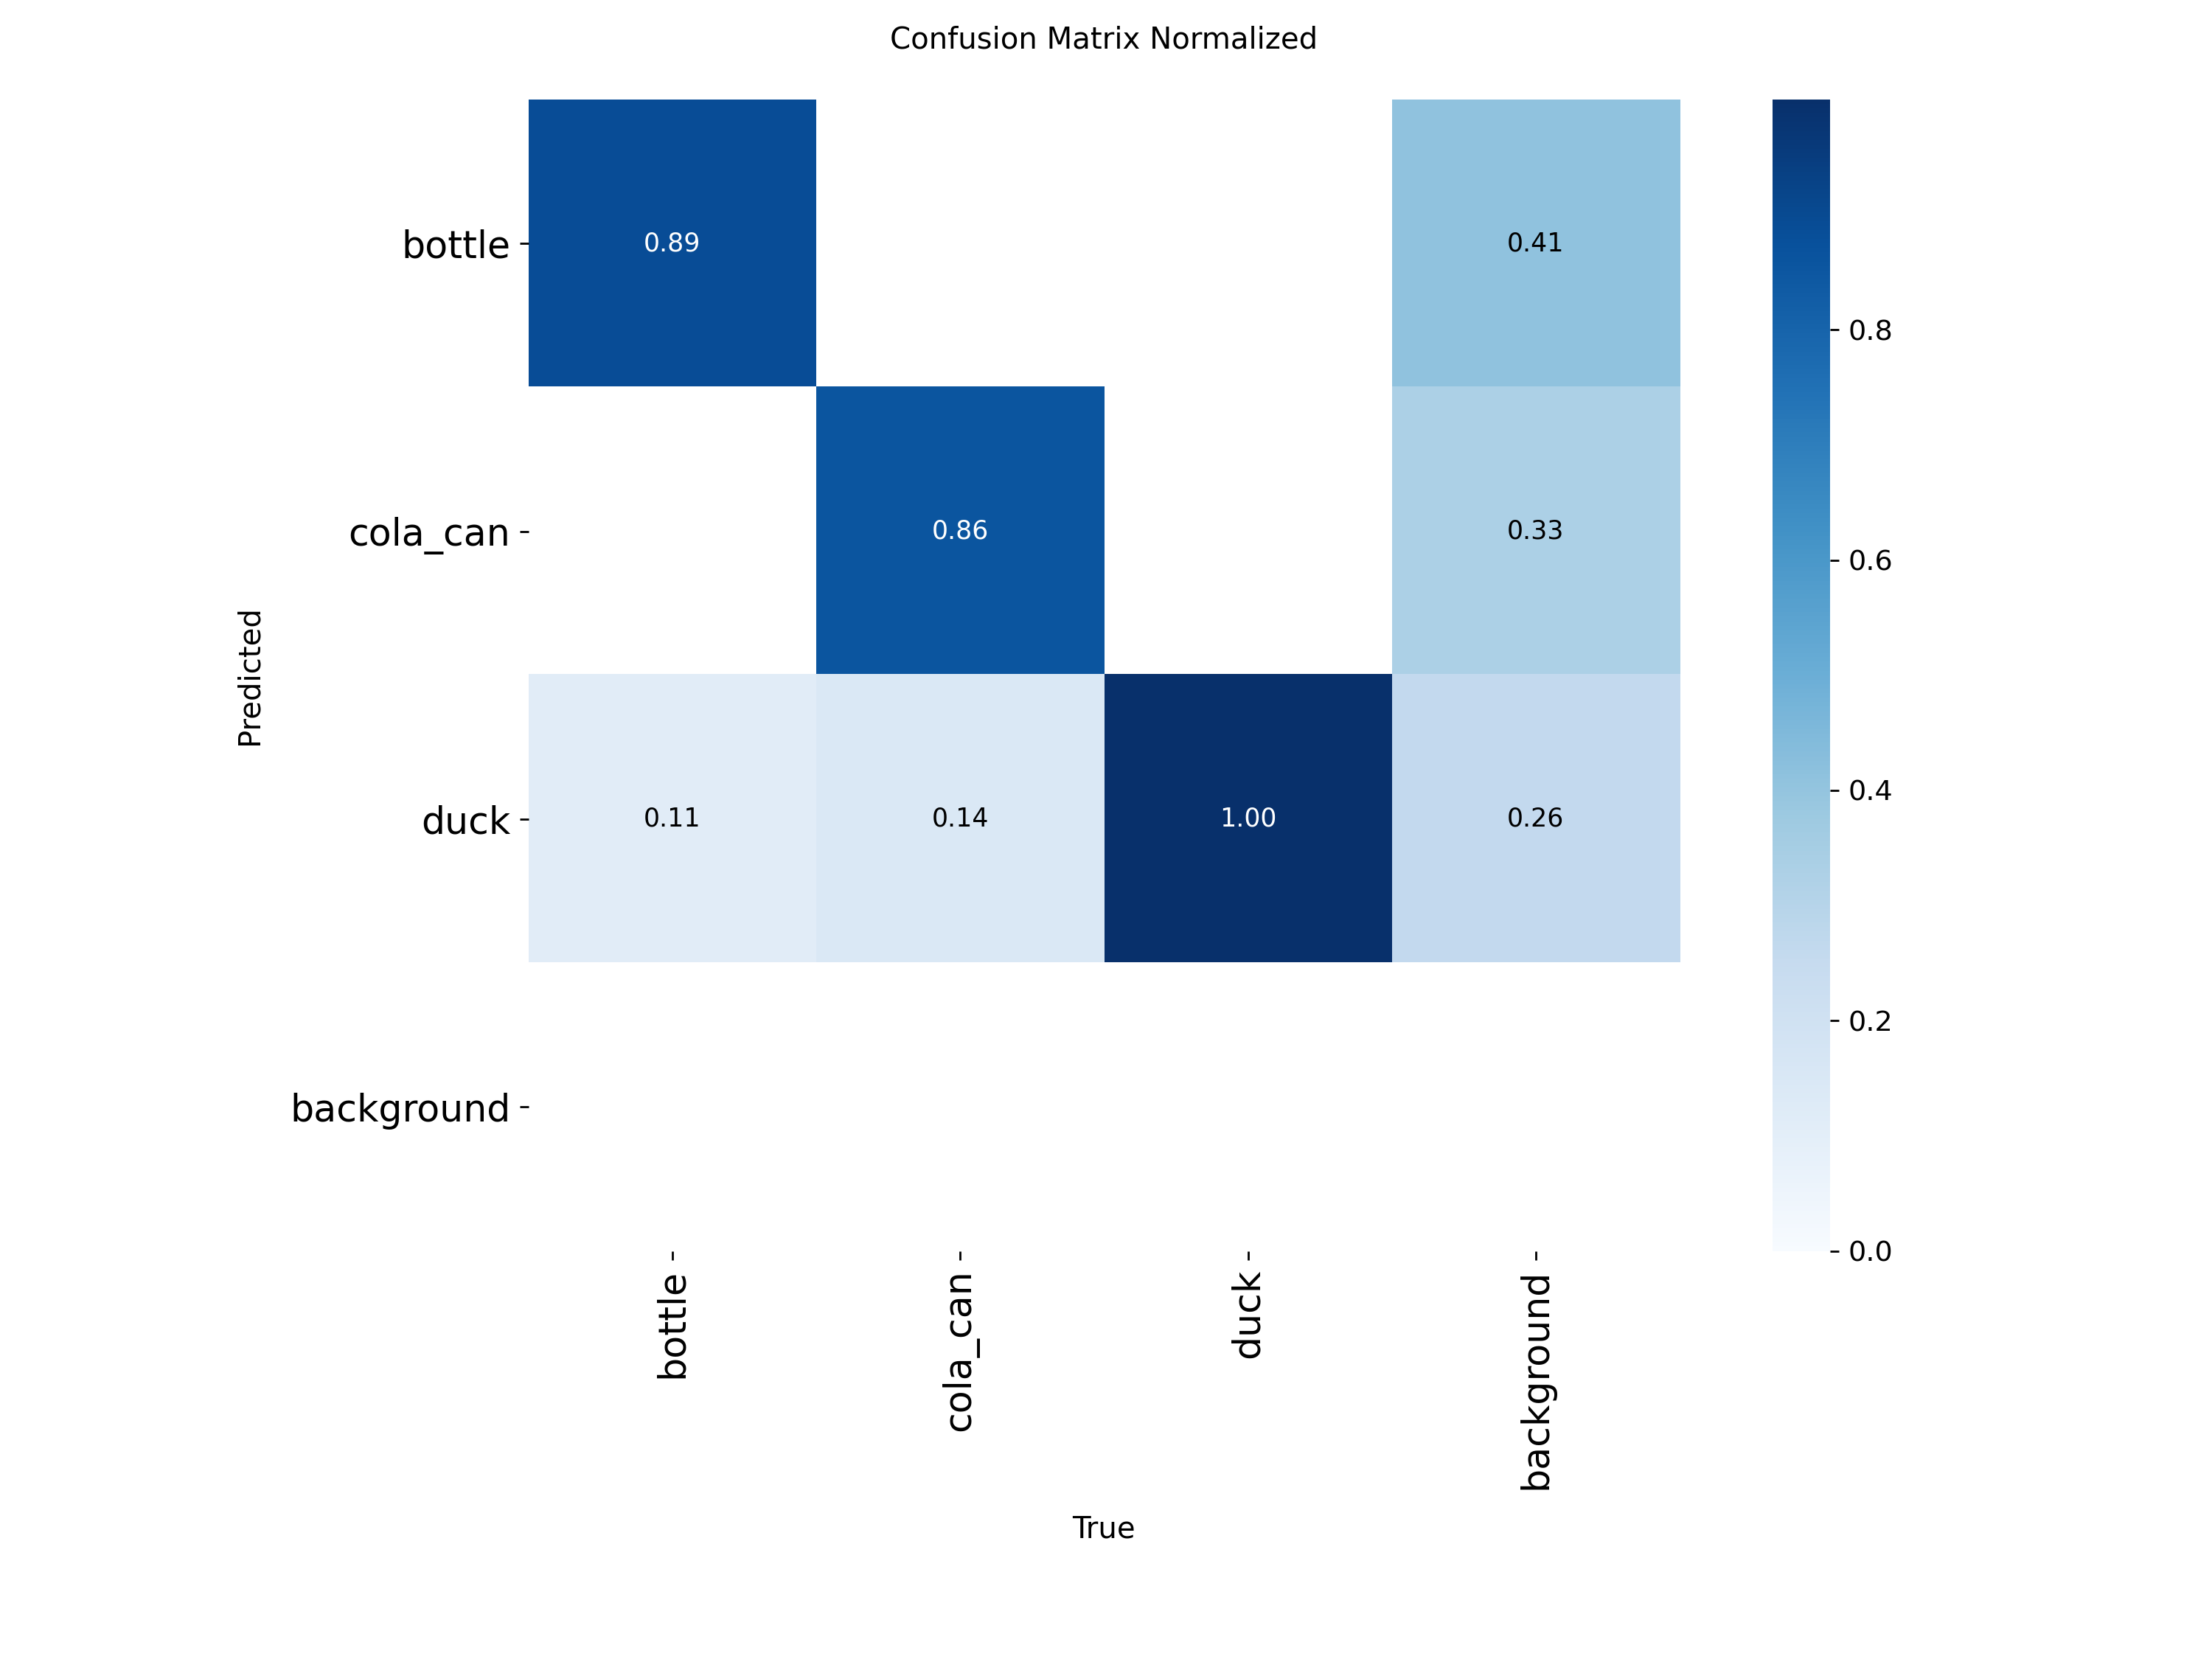

In [16]:
from IPython.display import display, Image
from pathlib import Path

# Training results
train_dir = Path('/content/yolo_runs/part2')

# Evaluation results
val_dir = Path(metrics.save_dir)

# Display 10 training graphs
print("Training and Validation Graphs")

if (train_dir / 'results.png').exists():
    display(Image(filename=str(train_dir / 'results.png')))
else:
    print("Training graphs not found.")

# Display confusion matrices
for name in ['confusion_matrix.png',
             'confusion_matrix_normalized.png']:

    file = val_dir / name

    if file.exists():
        print(name)
        display(Image(filename=str(file)))

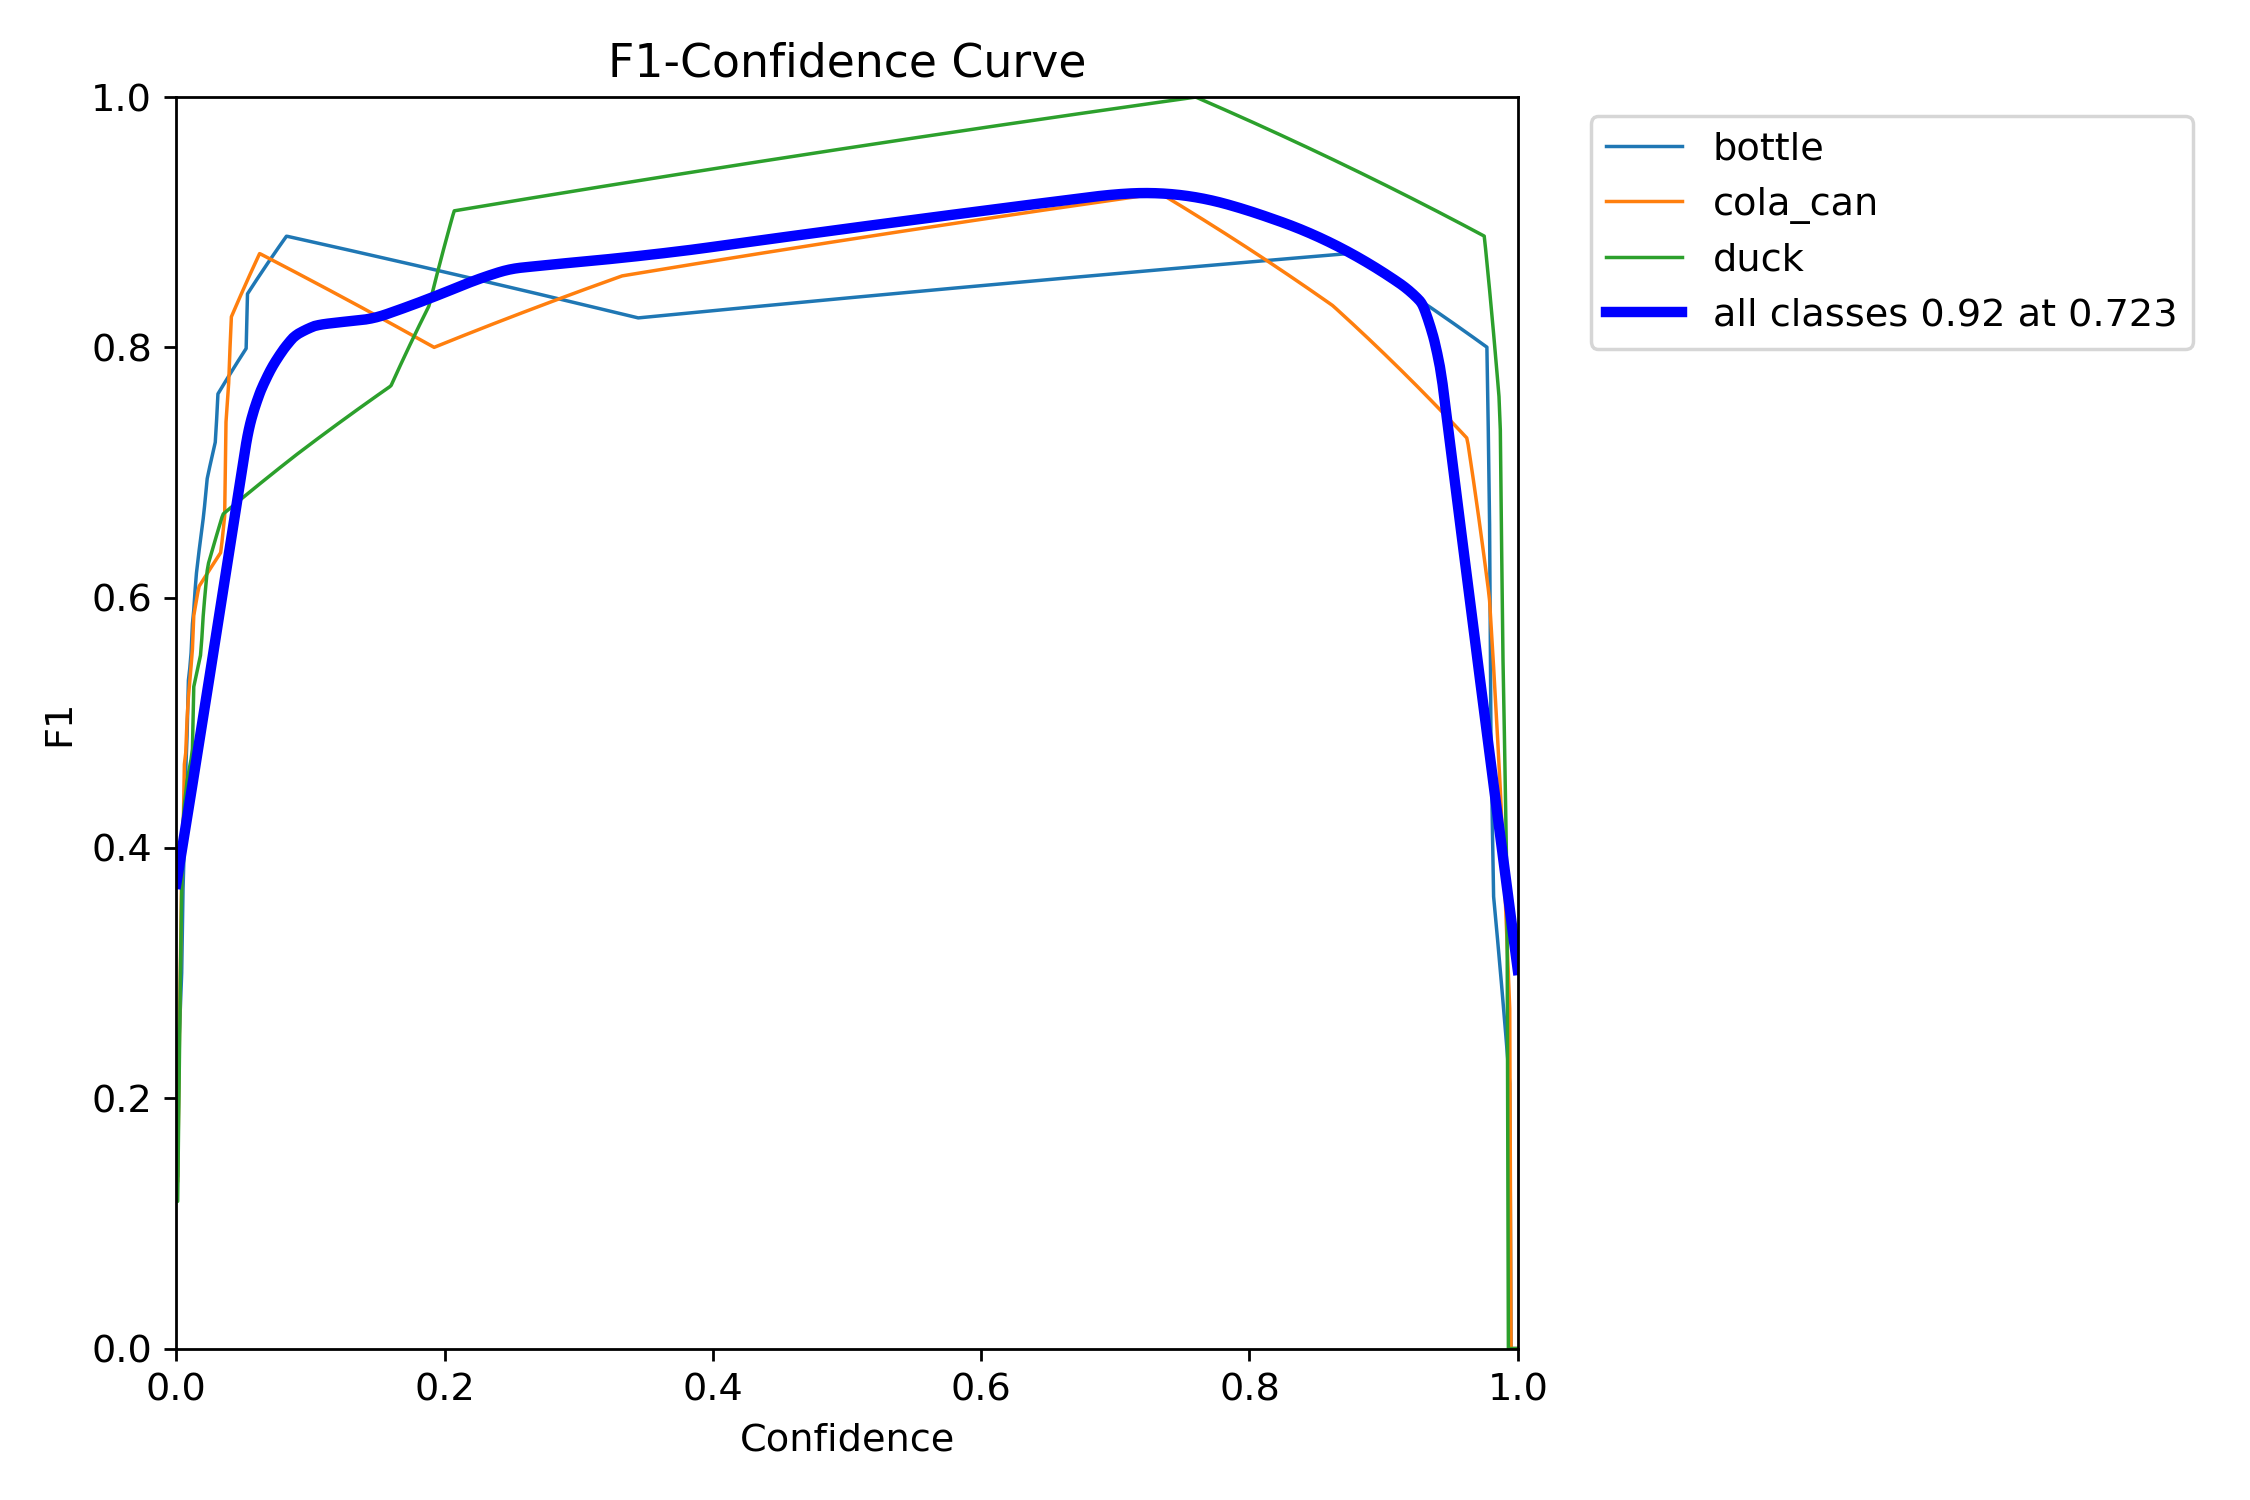

In [20]:
from IPython.display import display, Image as DisplayImage

display(DisplayImage(
    filename=str(metrics.save_dir / 'BoxF1_curve.png')
))

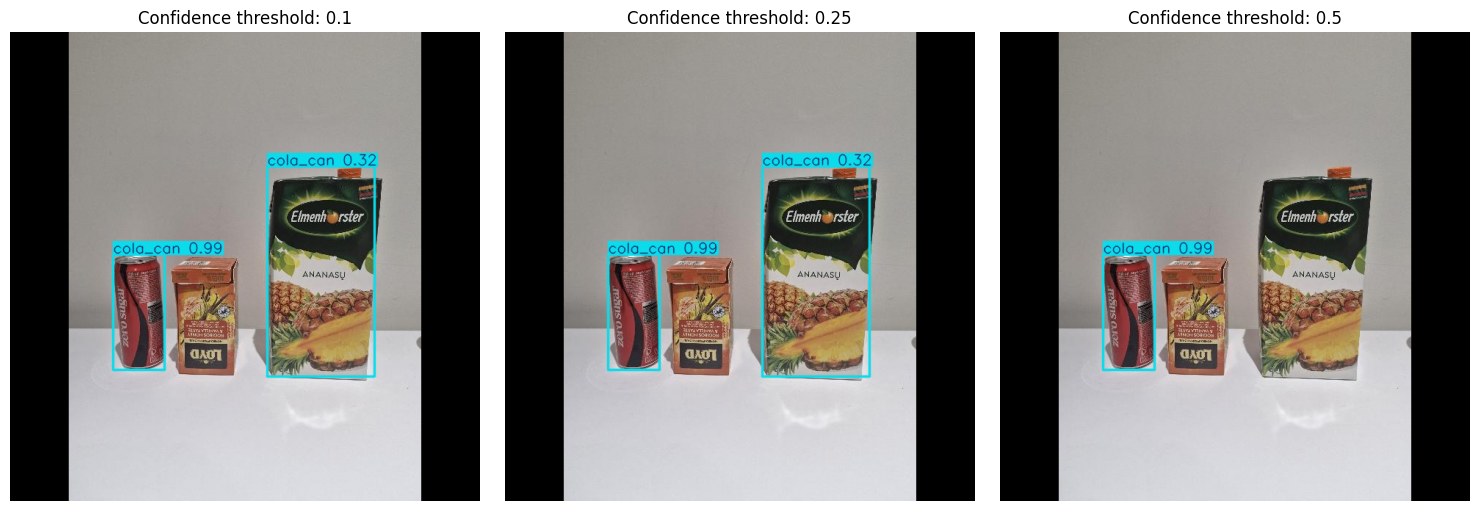

In [17]:
import matplotlib.pyplot as plt
from pathlib import Path

# Get test images
test_images = list(Path(dataset_path + '/test/images').glob('*.jpg'))

# Select one image
image = str(test_images[3])

plt.figure(figsize=(15, 5))

for i, conf in enumerate([0.1, 0.25, 0.5]):
    result = model.predict(image, conf=conf, verbose=False)[0]

    plt.subplot(1, 3, i + 1)
    plt.imshow(result.plot()[..., ::-1])
    plt.title(f"Confidence threshold: {conf}")
    plt.axis('off')

plt.tight_layout()
plt.show()

***Calculate IoU***

bottle: IoU = 0.989
Image: photo_5438493422667898631_w_jpg.rf.5d6892345389ecb9b4eebf510dd8f461.jpg
cola_can: IoU = 0.979
Image: photo_5438493422667898646_w_jpg.rf.37f0925ddce016dc2e639986e98fcd7b.jpg
duck: IoU = 0.965
Image: photo_5438493422667898594_w_jpg.rf.b4def2936df9ba2216ea5bca10859227.jpg


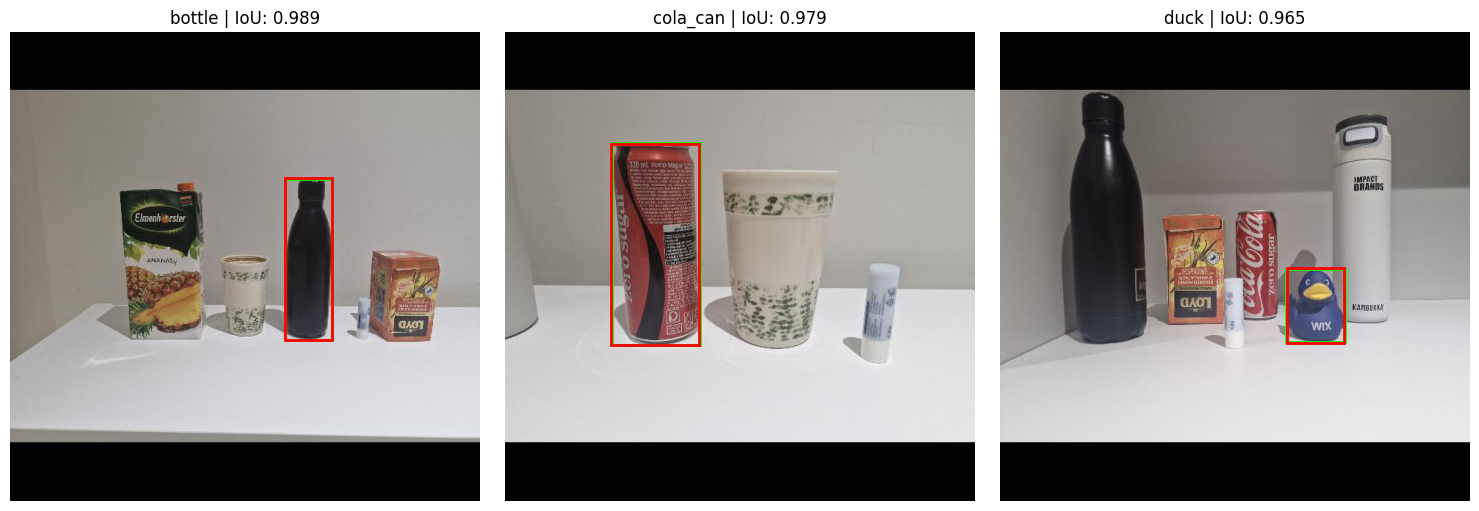

In [18]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
from ultralytics.utils.metrics import box_iou

plt.figure(figsize=(15, 5))

for class_id, name in model.names.items():

    # Find a suitable image
    for image_path in test_images:

        # Use only self-captured images for bottle
        if name == 'bottle' and not image_path.name.startswith('photo_'):
            continue

        label_path = Path(dataset_path + '/test/labels') / (image_path.stem + '.txt')

        if not label_path.exists():
            continue

        labels = [list(map(float, line.split()))
                  for line in label_path.read_text().splitlines()]

        objects = [row for row in labels if int(row[0]) == class_id]

        if not objects:
            continue

        result = model.predict(str(image_path), conf=0.25, verbose=False)[0]

        # For bottle, select a photo where YOLO detects a bottle
        if name == 'bottle' and not (result.boxes.cls.cpu() == class_id).any():
            continue

        break

    else:
        print(f"No suitable test image found for {name}")
        continue

    image = Image.open(image_path).convert('RGB')
    w, h = image.size

    # Actual bounding boxes
    actual_boxes = torch.tensor([
        [(x-bw/2)*w, (y-bh/2)*h,
         (x+bw/2)*w, (y+bh/2)*h]
        for c, x, y, bw, bh in objects
    ], dtype=torch.float32)

    # Predicted bounding boxes
    predicted_boxes = result.boxes.xyxy.cpu()
    predicted_boxes = predicted_boxes[result.boxes.cls.cpu() == class_id]

    # Calculate IoU
    if len(predicted_boxes) > 0:
        ious = box_iou(actual_boxes, predicted_boxes)
        scores = ious.max(dim=1).values
    else:
        scores = torch.zeros(len(actual_boxes))

    mean_iou = scores.mean().item()

    print(f"{name}: IoU = {mean_iou:.3f}")
    print(f"Image: {image_path.name}")

    # Display image and boxes
    plt.subplot(1, 3, class_id + 1)
    plt.imshow(image)

    for boxes, color in [(actual_boxes, 'lime'),
                         (predicted_boxes, 'red')]:

        for x1, y1, x2, y2 in boxes:
            plt.gca().add_patch(Rectangle(
                (x1, y1), x2-x1, y2-y1,
                fill=False, edgecolor=color, linewidth=2
            ))

    plt.title(f"{name} | IoU: {mean_iou:.3f}")
    plt.axis('off')

plt.tight_layout()
plt.show()